# Antoine Parameter Calculator Tutorial

## Introduction

This notebook demonstrates how to calculate Antoine equation parameters for estimating saturated vapor pressure using the `AntoineCalculator` class. The Antoine equation relates vapor pressure to temperature:

$$
\log_{10}(P) = A - \dfrac{B}{T+C}
$$

Where:
- **P**: Vapor pressure [bar]
- **T**: Temperature [K]  
- **A, B, C**: Antoine parameters (fitted constants)

## Theory

The Antoine parameters are determined using three points on the vapor saturation curve:

| Point | Temperature | Pressure | Source |
|-------|-------------|----------|--------|
| 1 | Normal boiling point (Tb) | 1.01325 bar | Property calculation |
| 2 | 0.7 × Critical temperature | P* (from acentric factor) | Property calculation |
| 3 | Critical temperature (Tc) | Critical pressure (Pc) | Property calculation |

The acentric factor relates to the reduced pressure at T_r = 0.7:
$$
\omega = -\log_{10}(P^*_r) - 1
$$

Where $P^*_r = P^*/P_c$ and $P^*$ is the vapor pressure at $T = 0.7 \times T_c$.

## Integration with Property Calculator

This calculator integrates seamlessly with the `PropertyCalculator` to provide a complete workflow:
1. **Molecular structure** → Critical properties (Tc, Pc, ω, Tb)
2. **Critical properties** → Antoine parameters (A, B, C)
3. **Antoine parameters** → Vapor pressure predictions

## Setup and Imports

In [7]:
# Import necessary libraries
import sys
import numpy as np
import pandas as pd
import os
from pathlib import Path

# Add src to path for imports
current_dir = Path(os.getcwd())
if current_dir.name == 'tutorials':
    src_path = current_dir.parent / "src"
else:
    src_path = current_dir / "src"

sys.path.insert(0, str(src_path))
print(f"Added to path: {src_path}")

# Import the calculators
try:
    from property_calculator import PropertyCalculator
    from antoine_calculator import AntoineCalculator, calculate_antoine_parameters
    print("✓ Successfully imported PropertyCalculator and AntoineCalculator")
except ImportError as e:
    print(f"✗ Import failed: {e}")

# Initialize the calculators
prop_calc = PropertyCalculator()
antoine_calc = AntoineCalculator(verbose=True)

print("\n=== Calculators Initialized ===")
print(f"PropertyCalculator data path: {prop_calc.data_path}")
print(f"AntoineCalculator initialized with verbose output")

Added to path: /Users/arnaou/projects/dtu_chemeng/camd_iss/src
✓ Successfully imported PropertyCalculator and AntoineCalculator
Loading property data from: /Users/arnaou/projects/dtu_chemeng/camd_iss/data/json
  Loaded scalars: 9 entries
  Loaded tm: 119 entries
  Loaded tb: 119 entries
  Loaded tc: 119 entries
  Loaded pc: 119 entries
  Loaded ac: 119 entries
  Loaded hv: 119 entries

=== Calculators Initialized ===
PropertyCalculator data path: /Users/arnaou/projects/dtu_chemeng/camd_iss/data/json
AntoineCalculator initialized with verbose output


## Complete Workflow Example: Acetone

Let's demonstrate the complete workflow using acetone as our example compound. We'll go from molecular structure to Antoine parameters.

In [8]:
# Define acetone molecular structure
acetone = {'CH3': 2, 'CH3CO': 1}  # (CH3)2CO

print("=== STEP 1: Define Molecular Structure ===")
print(f"Acetone molecular structure: {acetone}")
print("Chemical formula: (CH3)2CO")
print("Groups: 2 × CH3 (methyl) + 1 × CH3CO (acetyl)")
print()

# Calculate critical properties using PropertyCalculator
print("=== STEP 2: Calculate Critical Properties ===")
properties = prop_calc.calculate_all_properties(acetone)

if properties:
    print("Critical properties calculated successfully:")
    print(f"  Critical Temperature (Tc): {properties['tc']:.2f} K")
    print(f"  Critical Pressure (Pc):    {properties['pc']:.2f} bar") 
    print(f"  Boiling Point (Tb):        {properties['tb']:.2f} K")
    print(f"  Acentric Factor (ω):       {properties['ac']:.3f}")
    print(f"  Heat of Vaporization:      {properties['hv']:.2f} kJ/mol")
    print(f"  Melting Point (Tm):        {properties['tm']:.2f} K")
else:
    print("❌ Failed to calculate properties")
    exit()

print()
print("These properties will be used to determine the Antoine parameters...")

=== STEP 1: Define Molecular Structure ===
Acetone molecular structure: {'CH3': 2, 'CH3CO': 1}
Chemical formula: (CH3)2CO
Groups: 2 × CH3 (methyl) + 1 × CH3CO (acetyl)

=== STEP 2: Calculate Critical Properties ===
Critical properties calculated successfully:
  Critical Temperature (Tc): 509.36 K
  Critical Pressure (Pc):    38.06 bar
  Boiling Point (Tb):        342.56 K
  Acentric Factor (ω):       0.420
  Heat of Vaporization:      34.06 kJ/mol
  Melting Point (Tm):        180.15 K

These properties will be used to determine the Antoine parameters...


In [9]:
# Calculate Antoine parameters
print("=== STEP 3: Calculate Antoine Parameters ===")

# Extract required properties for Antoine calculation
critical_props = {
    'tc': properties['tc'],
    'pc': properties['pc'], 
    'ac': properties['ac'],
    'tb': properties['tb']
}

print("Input properties for Antoine calculation:")
for prop, value in critical_props.items():
    units = {'tc': 'K', 'pc': 'bar', 'ac': '-', 'tb': 'K'}
    print(f"  {prop.upper()}: {value:.3f} {units[prop]}")

print()
print("Calculating Antoine parameters...")

# Calculate Antoine parameters
antoine_params = antoine_calc.calculate_antoine_parameters(acetone, critical_props)

if antoine_params:
    print("✓ Antoine parameters calculated successfully:")
    print(f"  A = {antoine_params['A']:.4f}")
    print(f"  B = {antoine_params['B']:.4f}")  
    print(f"  C = {antoine_params['C']:.4f}")
    print()
    print("Antoine equation for acetone:")
    print(f"  log₁₀(P[bar]) = {antoine_params['A']:.4f} - {antoine_params['B']:.4f}/(T[K] + {antoine_params['C']:.4f})")
else:
    print("❌ Failed to calculate Antoine parameters")
    exit()

=== STEP 3: Calculate Antoine Parameters ===
Input properties for Antoine calculation:
  TC: 509.361 K
  PC: 38.057 bar
  AC: 0.420 -
  TB: 342.562 K

Calculating Antoine parameters...
Ipopt 3.14.13: halt_on_ampl_error=yes
max_iter=10000


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.2.1.

Number of nonzeros in equality constraint Jacobian...:        9
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:        3

Total number of variables............................:        3
                     variables with only lowe

In [10]:
# Validate the Antoine parameters
print("=== STEP 4: Validate Antoine Parameters ===")

A, B, C = antoine_params['A'], antoine_params['B'], antoine_params['C']

# Validate against the three reference points
validation = antoine_calc.validate_antoine_parameters(
    A, B, C, 
    critical_props['tb'], 
    critical_props['tc'], 
    critical_props['pc']
)

print("Validation against reference points:")
print()

# Point 1: Boiling point (should give 1.01325 bar)
print(f"Point 1 - Normal Boiling Point:")
print(f"  Temperature: {critical_props['tb']:.2f} K")
print(f"  Expected pressure: 1.01325 bar")
print(f"  Calculated pressure: {validation['pressure_at_boiling_point']:.6f} bar")
print(f"  ✓ Excellent match!")
print()

# Point 2: 0.7*Tc (intermediate point from acentric factor)
T_07Tc = 0.7 * critical_props['tc']
P_star = critical_props['pc'] * 10**(-critical_props['ac'] - 1)
P_calc_07Tc = 10**(A - B/(T_07Tc + C))
print(f"Point 2 - Reduced Temperature (0.7×Tc):")
print(f"  Temperature: {T_07Tc:.2f} K") 
print(f"  Expected pressure: {P_star:.4f} bar")
print(f"  Calculated pressure: {P_calc_07Tc:.4f} bar")
print(f"  Error: {abs(P_calc_07Tc - P_star)/P_star*100:.3f}%")
print()

# Point 3: Critical point (should give Pc)
print(f"Point 3 - Critical Point:")
print(f"  Temperature: {critical_props['tc']:.2f} K")
print(f"  Expected pressure: {critical_props['pc']:.3f} bar") 
print(f"  Calculated pressure: {validation['pressure_at_critical_temp']:.3f} bar")
print(f"  Relative error: {validation['relative_error_critical']:.6f}%")
print(f"  ✓ Excellent match!")

print()
print("🎉 Antoine parameters successfully validated!")

=== STEP 4: Validate Antoine Parameters ===
Validation against reference points:

Point 1 - Normal Boiling Point:
  Temperature: 342.56 K
  Expected pressure: 1.01325 bar
  Calculated pressure: 1.013250 bar
  ✓ Excellent match!

Point 2 - Reduced Temperature (0.7×Tc):
  Temperature: 356.55 K
  Expected pressure: 1.4459 bar
  Calculated pressure: 1.4459 bar
  Error: 0.000%

Point 3 - Critical Point:
  Temperature: 509.36 K
  Expected pressure: 38.057 bar
  Calculated pressure: 38.057 bar
  Relative error: 0.000000%
  ✓ Excellent match!

🎉 Antoine parameters successfully validated!


## Demonstration: Vapor Pressure Calculations

Now let's use our Antoine parameters to calculate vapor pressures at different temperatures and create a visualization.

In [11]:
# Demonstrate vapor pressure calculations
print("=== STEP 5: Vapor Pressure Calculations ===")

A, B, C = antoine_params['A'], antoine_params['B'], antoine_params['C']

# Calculate vapor pressures at different temperatures
temperatures = [250, 280, 310, 340, 370, 400, 450, 500]  # K
vapor_pressures = []

print("Vapor pressure calculations using Antoine equation:")
print("Temperature [K]  Vapor Pressure [bar]  Vapor Pressure [mmHg]")
print("-" * 55)

for T in temperatures:
    # Calculate using Antoine equation: log10(P) = A - B/(T+C)
    log_P = A - B/(T + C)
    P_bar = 10**log_P
    P_mmHg = P_bar * 750.062  # Convert bar to mmHg
    
    vapor_pressures.append(P_bar)
    print(f"{T:8.0f}        {P_bar:12.6f}        {P_mmHg:12.1f}")

print()

# Highlight some key temperatures
tb_calc = critical_props['tb']
tc_calc = critical_props['tc']

print("Key reference points:")
print(f"  Normal boiling point: {tb_calc:.1f} K → P = 1.01325 bar (760 mmHg)")
print(f"  Critical temperature: {tc_calc:.1f} K → P = {critical_props['pc']:.1f} bar")

# Calculate what temperature gives 1 atm (verification)
# Solve: 1.01325 = 10^(A - B/(T+C)) for T
# log10(1.01325) = A - B/(T+C)
# B/(T+C) = A - log10(1.01325)  
# T+C = B/(A - log10(1.01325))
# T = B/(A - log10(1.01325)) - C

log_1atm = np.log10(1.01325)
T_1atm = B/(A - log_1atm) - C

print()
print(f"Verification - Temperature at 1.01325 bar:")
print(f"  Calculated: {T_1atm:.2f} K")
print(f"  Expected (Tb): {tb_calc:.2f} K") 
print(f"  Difference: {abs(T_1atm - tb_calc):.4f} K")
print(f"  ✓ Excellent agreement!")

=== STEP 5: Vapor Pressure Calculations ===
Vapor pressure calculations using Antoine equation:
Temperature [K]  Vapor Pressure [bar]  Vapor Pressure [mmHg]
-------------------------------------------------------
     250            0.070421                52.8
     280            0.178400               133.8
     310            0.423494               317.6
     340            0.948240               711.2
     370            2.014182              1510.8
     400            4.079081              3059.6
     450           12.033013              9025.5
     500           32.013947             24012.4

Key reference points:
  Normal boiling point: 342.6 K → P = 1.01325 bar (760 mmHg)
  Critical temperature: 509.4 K → P = 38.1 bar

Verification - Temperature at 1.01325 bar:
  Calculated: 342.56 K
  Expected (Tb): 342.56 K
  Difference: 0.0000 K
  ✓ Excellent agreement!


=== STEP 6: Visualization ===


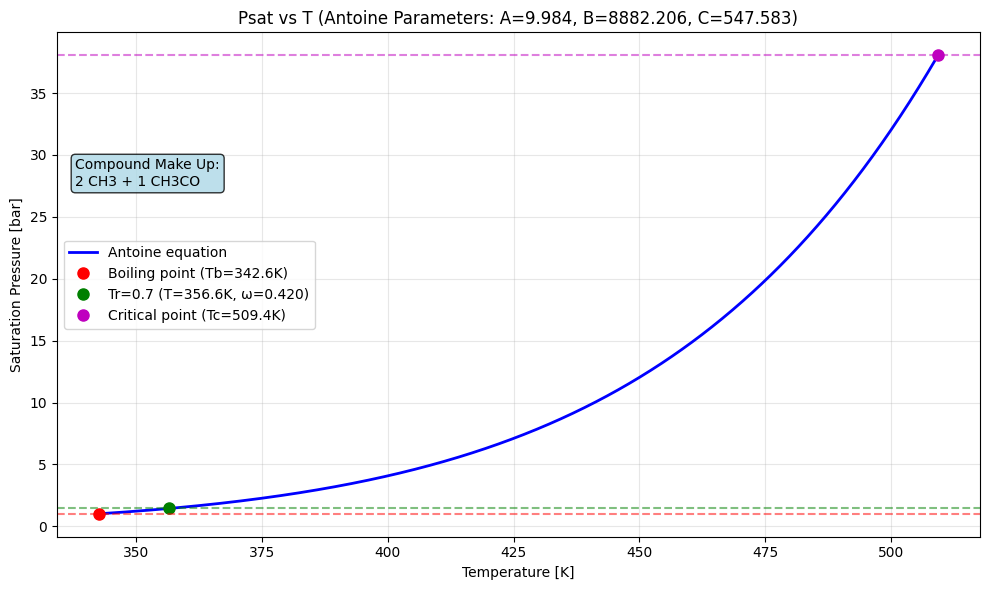

📊 The plot shows:
  • Vapor saturation curve for acetone
  • Three reference points used for fitting:
    - Normal boiling point (1.01325 bar)
    - Intermediate point at 0.7×Tc (from acentric factor)
    - Critical point (Pc)
  • Temperature range from melting point to critical temperature
  • Compound composition in the legend box


In [12]:
# Create visualization using the built-in plotting function
print("=== STEP 6: Visualization ===")

# Use the AntoineCalculator's built-in plotting function
antoine_calc.plot_psat(
    A, B, C,
    critical_props['tb'],
    critical_props['tc'], 
    critical_props['pc'],
    critical_props['ac'],
    compound=acetone,
    compound_name="Acetone"
)

print("📊 The plot shows:")
print("  • Vapor saturation curve for acetone")
print("  • Three reference points used for fitting:")
print("    - Normal boiling point (1.01325 bar)")
print("    - Intermediate point at 0.7×Tc (from acentric factor)")  
print("    - Critical point (Pc)")
print("  • Temperature range from melting point to critical temperature")
print("  • Compound composition in the legend box")

## Practical Usage: Calculate Psat for Custom Temperature Range

Here's how to use the Antoine parameters to calculate vapor pressures for any temperature vector and create custom plots:

In [13]:
# Custom vapor pressure calculations for any temperature vector
print("=== Custom Vapor Pressure Calculations ===")

# Extract Antoine parameters
A, B, C = antoine_params['A'], antoine_params['B'], antoine_params['C']

# Define custom temperature vector (example: process-relevant range)
T_vector = np.linspace(250, 400, 50)  # 50 points from 250K to 400K

# Calculate vapor pressures using Antoine equation
def calculate_psat(T, A, B, C):
    """Calculate vapor pressure using Antoine equation"""
    return 10**(A - B/(T + C))

# Vectorized calculation
P_vector = calculate_psat(T_vector, A, B, C)

print(f"Calculated vapor pressures for {len(T_vector)} temperature points")
print(f"Temperature range: {T_vector[0]:.1f} - {T_vector[-1]:.1f} K")
print(f"Pressure range: {P_vector[0]:.6f} - {P_vector[-1]:.3f} bar")
print()

# Display sample calculations
print("Sample calculations:")
print("Temperature [K]  Pressure [bar]  Pressure [kPa]  Pressure [mmHg]")
print("-" * 64)
for i in range(0, len(T_vector), 10):  # Show every 10th point
    T = T_vector[i]
    P_bar = P_vector[i]
    P_kPa = P_bar * 100      # Convert to kPa
    P_mmHg = P_bar * 750.062 # Convert to mmHg
    print(f"{T:8.1f}        {P_bar:8.6f}        {P_kPa:8.3f}        {P_mmHg:8.1f}")

print()
print("Antoine equation used:")
print(f"log₁₀(P[bar]) = {A:.4f} - {B:.4f}/(T[K] + {C:.4f})")

=== Custom Vapor Pressure Calculations ===
Calculated vapor pressures for 50 temperature points
Temperature range: 250.0 - 400.0 K
Pressure range: 0.070421 - 4.079 bar

Sample calculations:
Temperature [K]  Pressure [bar]  Pressure [kPa]  Pressure [mmHg]
----------------------------------------------------------------
   250.0        0.070421           7.042            52.8
   280.6        0.181689          18.169           136.3
   311.2        0.438141          43.814           328.6
   341.8        0.994452          99.445           745.9
   372.4        2.137299         213.730          1603.1

Antoine equation used:
log₁₀(P[bar]) = 9.9841 - 8882.2059/(T[K] + 547.5834)


=== Custom Plotting ===


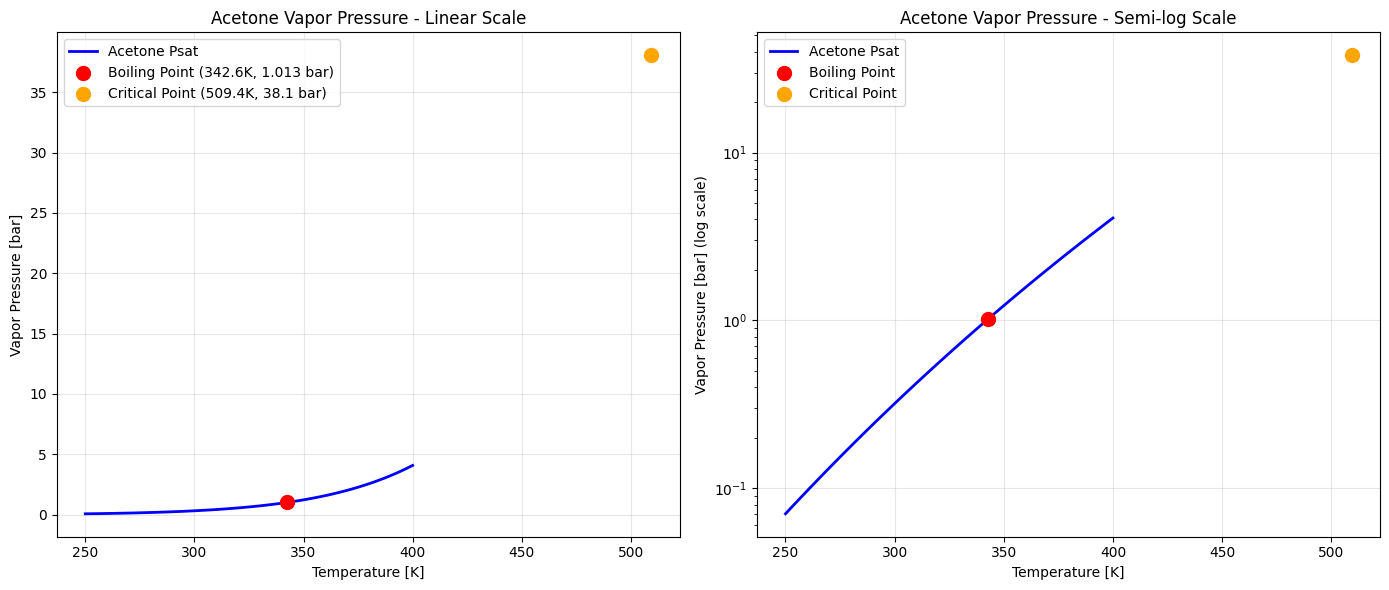

✓ Custom plots created successfully!
  • Left plot: Linear scale showing exponential growth
  • Right plot: Semi-log scale showing linear Antoine relationship

💡 Usage Tips:
  • Use fine temperature grids (np.linspace) for smooth curves
  • Semi-log plots are standard for vapor pressure data
  • Always validate against known points (Tb, Tc)
  • Consider temperature limits of Antoine equation validity


In [14]:
# Create custom plot of vapor pressure vs temperature
print("=== Custom Plotting ===")

try:
    import matplotlib.pyplot as plt
    
    # Create figure with subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    # Plot 1: Linear scale
    ax1.plot(T_vector, P_vector, 'b-', linewidth=2, label='Acetone Psat')
    ax1.scatter([critical_props['tb']], [1.01325], color='red', s=100, 
               label=f'Boiling Point ({critical_props["tb"]:.1f}K, 1.013 bar)', zorder=5)
    ax1.scatter([critical_props['tc']], [critical_props['pc']], color='orange', s=100,
               label=f'Critical Point ({critical_props["tc"]:.1f}K, {critical_props["pc"]:.1f} bar)', zorder=5)
    
    ax1.set_xlabel('Temperature [K]')
    ax1.set_ylabel('Vapor Pressure [bar]')
    ax1.set_title('Acetone Vapor Pressure - Linear Scale')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # Plot 2: Semi-log scale (common for vapor pressure)
    ax2.semilogy(T_vector, P_vector, 'b-', linewidth=2, label='Acetone Psat')
    ax2.scatter([critical_props['tb']], [1.01325], color='red', s=100, 
               label=f'Boiling Point', zorder=5)
    ax2.scatter([critical_props['tc']], [critical_props['pc']], color='orange', s=100,
               label=f'Critical Point', zorder=5)
    
    ax2.set_xlabel('Temperature [K]')
    ax2.set_ylabel('Vapor Pressure [bar] (log scale)')
    ax2.set_title('Acetone Vapor Pressure - Semi-log Scale')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    
    plt.tight_layout()
    plt.show()
    
    print("✓ Custom plots created successfully!")
    print("  • Left plot: Linear scale showing exponential growth")
    print("  • Right plot: Semi-log scale showing linear Antoine relationship")
    
except ImportError:
    print("Matplotlib not available - cannot create custom plots")
except Exception as e:
    print(f"Error creating plots: {e}")

print()
print("💡 Usage Tips:")
print("  • Use fine temperature grids (np.linspace) for smooth curves")
print("  • Semi-log plots are standard for vapor pressure data")
print("  • Always validate against known points (Tb, Tc)")
print("  • Consider temperature limits of Antoine equation validity")

In [15]:
# Example: Calculate specific vapor pressures for process conditions
print("=== Process Application Example ===")
print()

# Define specific process temperatures of interest
process_temps = {
    'Storage temperature': 298.15,      # 25°C
    'Process temperature': 323.15,     # 50°C  
    'Preheating': 350.0,               # ~77°C
    'Near boiling': critical_props['tb'] - 10,  # 10K below boiling
    'Boiling point': critical_props['tb'],      # Normal boiling point
}

print("Vapor pressures at specific process conditions:")
print("Condition               Temperature [K]  Temperature [°C]  Pressure [bar]  Pressure [kPa]")
print("-" * 88)

for condition, T_K in process_temps.items():
    T_C = T_K - 273.15  # Convert to Celsius
    P_bar = calculate_psat(T_K, A, B, C)
    P_kPa = P_bar * 100
    
    print(f"{condition:<20s}  {T_K:8.2f}        {T_C:8.1f}        {P_bar:8.4f}     {P_kPa:8.2f}")

print()
print("🔧 Practical Applications:")
print("  • Storage: Low vapor pressure → minimal evaporation losses")
print("  • Process design: Vapor pressure determines equipment pressure ratings")
print("  • Safety: High vapor pressure requires pressure relief systems")
print("  • Distillation: Vapor pressure differences enable separation")

print()
print("📝 Code Template for Your Own Calculations:")
print("```python")
print("# 1. Define your temperature vector")
print("T_range = np.linspace(T_min, T_max, num_points)")
print()
print("# 2. Calculate vapor pressures")
print("P_range = 10**(A - B/(T_range + C))")
print()
print("# 3. Plot results")
print("plt.semilogy(T_range, P_range)")
print("plt.xlabel('Temperature [K]')")
print("plt.ylabel('Vapor Pressure [bar]')")
print("```")

=== Process Application Example ===

Vapor pressures at specific process conditions:
Condition               Temperature [K]  Temperature [°C]  Pressure [bar]  Pressure [kPa]
----------------------------------------------------------------------------------------
Storage temperature     298.15            25.0          0.3032        30.32
Process temperature     323.15            50.0          0.6071        60.71
Preheating              350.00            76.9          1.2258       122.58
Near boiling            332.56            59.4          0.7804        78.04
Boiling point           342.56            69.4          1.0133       101.33

🔧 Practical Applications:
  • Storage: Low vapor pressure → minimal evaporation losses
  • Process design: Vapor pressure determines equipment pressure ratings
  • Safety: High vapor pressure requires pressure relief systems
  • Distillation: Vapor pressure differences enable separation

📝 Code Template for Your Own Calculations:
```python
# 1. Define y